# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [ ]:
STUDENT_NAME = 'Олійник Божена Орестівна'    
LIST_NUMBER  = 7

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам’янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 7: Івано-Франківськ, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

встановлюю: osmnx, geopandas, shapely, pyproj, pyarrow, folium, mapclassify, h3 ...
усі пакети на місці


In [ ]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas 
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_івано-франківськ


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0, b0 = time.time(), cache_bytes()          
    raw = getter()                             
    clean(raw).to_parquet(path, index=False)      
    g = gpd.read_parquet(path)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),  
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 40.6 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 12085 | ребер 34132


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
display(pd.DataFrame(COST).T)

man = json.load(open(os.path.join(OUT, 'manifest.json'), encoding='utf-8'))
live = {k: {'секунд': man[k]['секунд'], 'передано_МБ': man[k]['передано_МБ']}
        for k in ['boundary', 'heritage', 'stations', 'amenities']}
live['мережа walk'] = {'секунд': man['road_nodes']['секунд'] + man['road_edges']['секунд'],
                       'передано_МБ': man['road_nodes']['передано_МБ']}
cmp_ = pd.DataFrame({
    'живий запит, с':   {k: v['секунд'] for k, v in live.items()},
    'передано, МБ':     {k: v['передано_МБ'] for k, v in live.items()},
    'знімок, с':        {k: COST[k]['секунд'] for k in live},
    'файл знімка, МБ':  {k: COST[k]['файл_МБ'] for k in live},
})
cmp_.loc['РАЗОМ'] = cmp_.sum()
cmp_['знімок швидше, разів'] = (cmp_['живий запит, с'] / cmp_['знімок, с'].clip(lower=1e-3)).round(0)
display(cmp_)
print('дата живого запиту:', man['_дата'], '| увесь збір скриптом: %.0f с' % man['_секунд_усього'])
print('при повторному запуску не передано мережею: %.2f МБ' % cmp_.loc['РАЗОМ', 'передано, МБ'])

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.029,1.424
heritage,знімок,1242,0.0,0.23,0.075
stations,знімок,9,0.0,0.063,0.064
amenities,знімок,616,0.0,0.111,0.053
мережа walk,знімок,46217,0.0,2.294,0.156


,"живий запит, с","передано, МБ","знімок, с","файл знімка, МБ","знімок швидше, разів"
boundary,1.5,0.021,1.424,0.029,1.0
heritage,92.0,1.060,0.075,0.230,1227.0
stations,77.5,0.015,0.064,0.063,1211.0
amenities,95.9,0.238,0.053,0.111,1809.0
мережа walk,79.2,5.402,0.156,2.294,508.0
РАЗОМ,346.1,6.736,1.772,2.727,195.0


дата живого запиту: 2026-10-31 22:31 | увесь збір скриптом: 348 с
при повторному запуску не передано мережею: 6.74 МБ


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
mask     = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)   # об'єднання умов
has_name = heritage['name'].notna() & (heritage['name'].astype(str).str.strip() != '')

cand = heritage[mask & has_name].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))
print('відкинуто без name     :', int((mask & ~has_name).sum()))
print('відкинуто за тегами    :', int((~mask).sum()))

dropped = heritage[mask & ~has_name]
print()
print('=== відкинуті безіменні, за historic ===')
print(dropped['historic'].value_counts(dropna=False).to_string())
print()
print('=== відкинуті безіменні, за tourism ===')
print(dropped['tourism'].value_counts(dropna=False).to_string())
print()
print('типи геометрії відкинутих:', dropped.geometry.geom_type.value_counts().to_dict())
print('з них мають wikidata    :', int(dropped['wikidata'].notna().sum()))

усього у шарі heritage : 1242
підходять за тегами    : 1242
з них мають name       : 294
відкинуто без name     : 948
відкинуто за тегами    : 0

=== відкинуті безіменні, за historic ===
historic
heritage          867
memorial           37
None               21
wayside_shrine      8
wayside_cross       6
door                5
ruins               3
stone               1

=== відкинуті безіменні, за tourism ===
tourism
None       927
artwork     19
museum       1
gallery      1

типи геометрії відкинутих: {'Polygon': 872, 'Point': 76}
з них мають wikidata    : 0


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial          173
heritage           34
wayside_shrine     13
castle              3
wayside_cross       1
monument            1

=== tourism ===
tourism
artwork       53
museum        12
attraction     4
viewpoint      1
hotel          1

типи геометрії: {'Point': 249, 'Polygon': 45}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

NAME_COLS = [c for c in cand.columns if c.startswith('name:')]

cand['wiki']   = (cand['wikidata'].notna() | cand['wikipedia'].notna()).astype(int)
cand['n_lang'] = cand[NAME_COLS].notna().sum(axis=1)
cand['visit']  = cand['tourism'].isin(['museum', 'gallery', 'attraction', 'viewpoint']).astype(int)
cand['hist']   = cand['historic'].notna().astype(int)

cand['n_lang_pct'] = cand['n_lang'].rank(pct=True, method='min')
cand['area_pct']   = cand['area_m2'].rank(pct=True, method='min')

W = {'wiki': 0.35, 'n_lang_pct': 0.25, 'visit': 0.20, 'hist': 0.10, 'area_pct': 0.10}
cand['score'] = sum(w * cand[c] for c, w in W.items())

print('ваги         :', W)
print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мають name:* :', int((cand['n_lang'] > 0).sum()))
print('для відвідування (museum/gallery/attraction/viewpoint):', int(cand['visit'].sum()))
print('мають historic:', int(cand['hist'].sum()))
print('полігонів    :', int((cand['area_m2'] > 0).sum()))

ваги         : {'wiki': 0.35, 'n_lang_pct': 0.25, 'visit': 0.2, 'hist': 0.1, 'area_pct': 0.1}
кандидатів   : 294
мають wiki   : 27
мають name:* : 273
для відвідування (museum/gallery/attraction/viewpoint): 17
мають historic: 225
полігонів    : 45


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

top_score = cand.nlargest(N_LARGE, 'score')
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2')
overlap   = len(set(top10.index) & set(top_naive.index))
top_score = top_score.reset_index(drop=True)
top10     = top10.reset_index(drop=True)
top_naive = top_naive.reset_index(drop=True)

print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'score': list(top10['score'].round(3)),
                      'за площею': list(top_naive['name']),
                      'площа, м²': list(top_naive['area_m2'].round(0))}))

перетин: 3 з 10


,за вашим критерієм,score,за площею,"площа, м²"
0,Бастіон Станіславівської фортеці,0.995,Палац Потоцьких,14934.0
1,Палац Потоцьких,0.796,Бастіон Станіславівської фортеці,3116.0
2,Палац Ромашканів,0.791,Залізничний вокзал,2918.0
3,Свято-Троїцький Кафедральний собор,0.779,Івано-Франківський міський суд,2701.0
4,Музей мистецтв Прикарпаття,0.731,Пасаж Гартенбергів,2389.0
5,Ратуша,0.729,Центральний корпус ІФНМУ,1709.0
6,Архикатедральний Собор Святого Воскресіння,0.728,Морфологічний корпус ІФНМУ,1387.0
7,Катедральний Собор Покрови Пресвятої Богородиці,0.726,Ратуша,1335.0
8,Церква Царя Христа,0.725,Костел Христа Царя,1246.0
9,Синагога Темпель,0.724,Стоматологічний корпус ІФНМУ,1126.0


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [ ]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

def show_pairs(gdf, pairs):
    rows = [{'i': i, 'об’єкт i': gdf['name'].iloc[i],
             'теги i': '%s / %s' % (gdf['historic'].iloc[i], gdf['tourism'].iloc[i]),
             'j': j, 'об’єкт j': gdf['name'].iloc[j],
             'теги j': '%s / %s' % (gdf['historic'].iloc[j], gdf['tourism'].iloc[j]),
             'м': round(d, 1),
             'wikidata i / j': '%s / %s' % (gdf['wikidata'].iloc[i], gdf['wikidata'].iloc[j])}
            for i, j, d in pairs]
    return pd.DataFrame(rows)

from shapely.geometry import Point
_test = gpd.GeoDataFrame(geometry=[Point(24.7111, 48.9226), Point(24.7115, 48.9226)], crs='EPSG:4326')
print('тест на близьких точках:', [(i, j, round(d, 1)) for i, j, d in close_pairs(_test)])

pairs30 = close_pairs(top_score)
print('пар ближче 60 м у top_score:', len(pairs30))
display(show_pairs(top_score, pairs30))

тест на близьких точках: [(0, 1, np.float64(29.3))]
пар ближче 60 м у top_score: 4


,i,об’єкт i,теги i,j,об’єкт j,теги j,м,wikidata i / j
0,22,Юрій Баран,memorial / None,23,Дмитро Ломей,memorial / None,9.3,None / None
1,10,Музей Олекси Довбуша,None / museum,11,Народний музей освіти Прикарпаття,None / museum,32.7,Q12073711 / Q12132467
2,15,Люм'єр,heritage / None,18,Пам'ятник пластунам,memorial / None,40.6,Q12119375 / Q12138487
3,5,Ратуша,heritage / None,26,Яйце,None / artwork,44.3,Q3329061 / Q12165970


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 9
                                      name  railway       building
0                         Івано-Франківськ  station           None
1  Автостанція "Івано-Франківськ-1" (АС-1)     None           None
2                                 Бистриця     halt           None
3  Автостанція "Івано-Франківськ-3" (АС-3)     None           None
4                                 Бистриця     halt           None
5     Місце відправлення автобуса до Лисця     None           None
6  Автостанція "Івано-Франківськ-2" (АС-2)     None           None
7                       Залізничний вокзал     None  train_station
8                                 Бистриця     halt            yes


In [ ]:
station = stations[stations['building'] == 'train_station'].head(1)
rail    = stations[(stations['railway'] == 'station')].head(1)
d_sr = station.to_crs(32635).geometry.representative_point().iloc[0].distance(
       rail.to_crs(32635).geometry.iloc[0])
print('старт:', station['name'].iloc[0])
print('до вузла railway=station «%s»: %.0f м' % (rail['name'].iloc[0], d_sr))

старт: Залізничний вокзал
до вузла railway=station «Івано-Франківськ»: 29 м


In [ ]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 12085 вузлів, 33787 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
def check_snap(points, ids, dist, label):
    n_pts, n_nodes = len(ids), len(set(ids))
    print('[%s] точок: %d | різних вузлів: %d' % (label, n_pts, n_nodes))
    k = int(np.argmax(dist))
    print('[%s] точка -> вузол: медіана %.1f м, максимум %.1f м (%s)'
          % (label, float(np.median(dist)), float(dist[k]), points['name'].iloc[k]))
    if n_nodes < n_pts:
        groups = collections.defaultdict(list)
        for i, nd in enumerate(ids):
            groups[nd].append(points['name'].iloc[i])
        print('[%s] УВАГА: злиплись на одному вузлі:' % label)
        for nd, names in groups.items():
            if len(names) > 1:
                print('   вузол %s: %s' % (nd, ' | '.join(names)))
    else:
        print('[%s] злиплих точок немає' % label)
    return n_nodes == n_pts

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [ ]:
def road_matrix(ids):
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    off = ~np.eye(len(D), dtype=bool)
    ok = off & np.isfinite(D) & (E > 0)
    return float(np.median(D[ok] / E[ok]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

[мала задача] точок: 11 | різних вузлів: 11
[мала задача] точка -> вузол: медіана 21.5 м, максимум 42.7 м (Архикатедральний Собор Святого Воскресіння)
[мала задача] злиплих точок немає
матриця за 0.459 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.27


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [ ]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    k = len(D)
    tour, left = [0], set(range(1, k))
    while left:
        cur = tour[-1]
        nxt = min(left, key=lambda j: D[cur, j])
        tour.append(nxt); left.remove(nxt)
    return tour + [0]

def two_opt(D, tour):
    best = list(tour)
    L = tour_length(D, best)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):          
            for j in range(i + 1, len(best) - 1):
                new = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                Ln = tour_length(D, new)         
                if Ln < L - 1e-9:
                    best, L, improved = new, Ln, True
    return best

In [ ]:
def held_karp(D):
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,9542,3.56
2-opt,9353,1.52
Held-Karp (точний),9214,0.00



оптимальний порядок:
   0. СТАРТ: Залізничний вокзал
   1. Церква Царя Христа
   2. Палац Ромашканів
   3. Архикатедральний Собор Святого Воскресіння
   4. Бастіон Станіславівської фортеці
   5. Музей мистецтв Прикарпаття
   6. Ратуша
   7. Синагога Темпель
   8. Катедральний Собор Покрови Пресвятої Богородиці
   9. Палац Потоцьких
  10. Свято-Троїцький Кафедральний собор
  11. СТАРТ: Залізничний вокзал

довжина: 9.21 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
growth = pd.DataFrame([{'точок n': n,
                        'клітин 2^(n-1)·(n-1)': float(2 ** (n - 1) * (n - 1)),
                        'пам’яті, ГБ (8 Б/клітина)': 2 ** (n - 1) * (n - 1) * 8 / 1e9,
                        'операцій 2^(n-1)·(n-1)²': float(2 ** (n - 1) * (n - 1) ** 2)}
                       for n in [11, 16, 21, 26, 31]]).set_index('точок n')
pd.options.display.float_format = '{:.3g}'.format
display(growth)
pd.options.display.float_format = None
n_big = N_LARGE + 1
print('велика задача: %d точок (вокзал + %d) -> %.1f ГБ лише на таблицю dp'
      % (n_big, N_LARGE, 2 ** (n_big - 1) * (n_big - 1) * 8 / 1e9))

,клітин 2^(n-1)·(n-1),"пам’яті, ГБ (8 Б/клітина)",операцій 2^(n-1)·(n-1)²
точок n,,,
11,1.02e+04,8.19e-05,1.02e+05
16,4.92e+05,0.00393,7.37e+06
21,2.1e+07,0.168,4.19e+08
26,8.39e+08,6.71,2.1e+10
31,3.22e+10,258,9.66e+11


велика задача: 31 точок (вокзал + 30) -> 257.7 ГБ лише на таблицю dp


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [32]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()

[велика задача] точок: 31 | різних вузлів: 30
[велика задача] точка -> вузол: медіана 17.6 м, максимум 42.7 м (Архикатедральний Собор Святого Воскресіння)
[велика задача] УВАГА: злиплись на одному вузлі:
   вузол 7934224633: Юрій Баран | Дмитро Ломей
коефіцієнт обходу: 1.22
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    24364 м
2-opt            :    20049 м  за 0.021 с  (коротше на 17.7%)



---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
кандидатів: 294 | непорожніх комірок: 87 | максимум у комірці: 24
половина всіх пам’яток зосереджена в 13 комірках з 87 (15%)


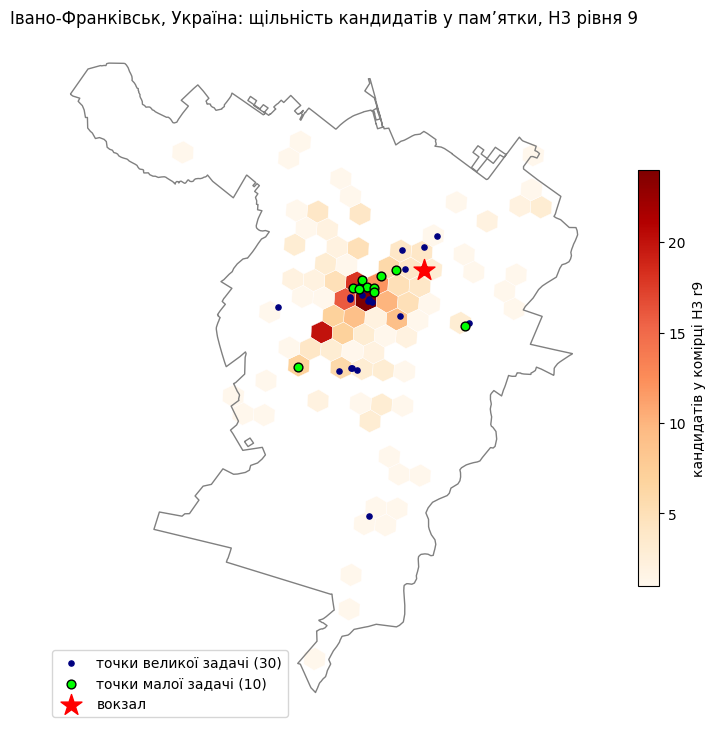

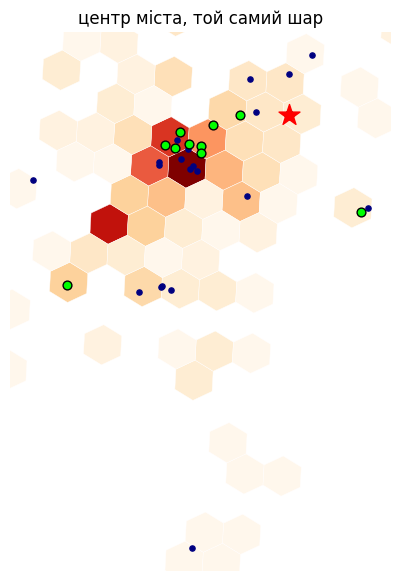

In [ ]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

rp = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in rp]    
dens = cand.groupby('h3').size().sort_values(ascending=False)
hexes = gpd.GeoDataFrame(
    {'h3': dens.index, 'n': dens.values},
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)])  
              for c in dens.index],
    crs='EPSG:4326')

cum = dens.cumsum() / dens.sum()
n_half = int((cum < 0.5).sum()) + 1
print('кандидатів: %d | непорожніх комірок: %d | максимум у комірці: %d'
      % (len(cand), len(dens), dens.max()))
print('половина всіх пам’яток зосереджена в %d комірках з %d (%.0f%%)'
      % (n_half, len(dens), 100 * n_half / len(dens)))

fig, ax = plt.subplots(figsize=(9, 9))
boundary.boundary.plot(ax=ax, color='grey', lw=1)
hexes.plot(ax=ax, column='n', cmap='OrRd', legend=True, edgecolor='white', lw=0.3,
           legend_kwds={'label': 'кандидатів у комірці H3 r9', 'shrink': 0.6})
pts30.plot(ax=ax, color='navy', markersize=14, label='точки великої задачі (30)')
pts10.plot(ax=ax, color='lime', edgecolor='black', markersize=40, label='точки малої задачі (10)')
pts10.iloc[[0]].plot(ax=ax, color='red', marker='*', markersize=250, label='вокзал')
ax.set_title('%s: щільність кандидатів у пам’ятки, H3 рівня %d' % (CITY, H3_RES))
ax.legend(loc='lower left'); ax.set_axis_off()
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
hexes.plot(ax=ax, column='n', cmap='OrRd', edgecolor='white', lw=0.3)
pts30.plot(ax=ax, color='navy', markersize=14)
pts10.plot(ax=ax, color='lime', edgecolor='black', markersize=40)
pts10.iloc[[0]].plot(ax=ax, color='red', marker='*', markersize=250)
xmin, ymin, xmax, ymax = pts30.total_bounds
ax.set_xlim(xmin - 0.003, xmax + 0.003); ax.set_ylim(ymin - 0.002, ymax + 0.002)
ax.set_title('центр міста, той самий шар'); ax.set_axis_off()
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [ ]:
pts_m = pts30.to_crs(32635)                                   
am_m  = amenities.to_crs(32635)[['name', 'amenity', 'geometry']].rename(
    columns={'name': 'заклад', 'amenity': 'тип'})

near = gpd.sjoin_nearest(pts_m, am_m, how='left', distance_col='відстань_м')
near = near[~near.index.duplicated(keep='first')]             
near['відстань_м'] = near['відстань_м'].round(0)
near['у малій задачі'] = near.index < len(pts10)
display(near[['name', 'заклад', 'тип', 'відстань_м', 'у малій задачі']]
        .rename(columns={'name': 'точка маршруту'}))
print('медіана відстані до найближчого закладу: %.0f м, максимум: %.0f м'
      % (near['відстань_м'].median(), near['відстань_м'].max()))

,точка маршруту,заклад,тип,відстань_м,у малій задачі
0,СТАРТ: Залізничний вокзал,None,toilets,12.0,True
1,Бастіон Станіславівської фортеці,Corassini Grill & Wine,restaurant,8.0,True
2,Палац Потоцьких,None,pharmacy,80.0,True
3,Палац Ромашканів,Franciszek Romaszkan,restaurant,5.0,True
4,Свято-Троїцький Кафедральний собор,Статус,cafe,29.0,True
5,Музей мистецтв Прикарпаття,Бізе,cafe,41.0,True
6,Ратуша,None,cafe,28.0,True
7,Архикатедральний Собор Святого Воскресіння,Clover,cafe,40.0,True
8,Катедральний Собор Покрови Пресвятої Богородиці,Canadian food,cafe,50.0,True
9,Церква Царя Христа,Мирофарм,pharmacy,58.0,True


медіана відстані до найближчого закладу: 40 м, максимум: 237 м


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [36]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

road_line = route_coords(ex10, ids10)                                 
straight_line = [(pts10.geometry.y.iloc[i], pts10.geometry.x.iloc[i]) for i in ex10]   

c = pts10.unary_union.centroid
fmap = folium.Map(location=[c.y, c.x], zoom_start=15, tiles=BASEMAP)
folium.PolyLine(road_line, color='crimson', weight=5, opacity=0.85,
                tooltip='маршрут по ребрах графа: %.2f км' % (L_opt / 1000)).add_to(fmap)
folium.PolyLine(straight_line, color='royalblue', weight=2, dash_array='6 6',
                tooltip='прямі відрізки: %.2f км' % (tour_length(E10, ex10) / 1000)).add_to(fmap)
for step, i in enumerate(ex10[:-1]):
    y, x = pts10.geometry.y.iloc[i], pts10.geometry.x.iloc[i]
    color = 'red' if i == 0 else 'darkgreen'
    folium.Marker([y, x], tooltip='%d. %s' % (step, pts10['name'].iloc[i]),
                  icon=folium.DivIcon(html='<div style="background:%s;color:white;border-radius:50%%;'
                                           'width:22px;height:22px;text-align:center;font:bold 12px/22px sans-serif">'
                                           '%d</div>' % (color, step))).add_to(fmap)
fmap.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:20px;left:20px;z-index:999;background:white;padding:6px 10px;'
    'border:1px solid #999;font:13px sans-serif"><b>%s</b><br>'
    '<span style="color:crimson">━━</span> по ребрах графа: %.2f км<br>'
    '<span style="color:royalblue">- - -</span> прямі відрізки: %.2f км<br>'
    'Дані © OpenStreetMap contributors, ODbL</div>'
    % (CITY, L_opt / 1000, tour_length(E10, ex10) / 1000)))
fmap.save('lr5_маршрут.html')
print('по ребрах графа: %.2f км | прямими відрізками: %.2f км | відношення %.2f'
      % (L_opt / 1000, tour_length(E10, ex10) / 1000, L_opt / tour_length(E10, ex10)))
print('точок у лінії по графу: %d, у прямій: %d' % (len(road_line), len(straight_line)))
fmap

по ребрах графа: 9.21 км | прямими відрізками: 7.39 км | відношення 1.25
точок у лінії по графу: 243, у прямій: 12


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [30]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.2 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

1. Відкинуто 948 об'єктів без назви, замовнику обов'язково потрібно ояснити, чому вони не потрапили у вибірку, оскільки відкидання такої великої кількості записів може видатиь дивним людині, яка не знає ому таке рішення було прийнято.
2. Стаття у Вікіпедії - 0.35, якщо про пам'ятку написали статтю і вікіпедії - вона визнана іншими людьми за межами нашого набору даних. Скільки перекладів назви на інші мови є - 0.25, пам'яткою цікавлться іноземці. Visit (музей, галерея, оглдовий майданчик, тощо) - 0.2, памєятка офіційно призначеня для відвідування. Hist - 0.1, пам'ятка несе історичну цінність, не дуже важлива, оскільки багато місць може бути позначеними важливими історично, проте насправді не бути "цікавими". Площа - 0.1, площа, яку займає пам'ятка, не дуже важлива.
3. Збіглося 3 об'єкти, це означає, що об1єкт стає найкращим не за площею, яку він займає, а за іншими критеріями, які здебільшого визначають одне - популряність пам'ятки серед туристів.
4. На малій задачі коефіцієнт обходу - 1.27, на великій - 1.22. Це типове значення, більшість пам'яток зоереджені в центральній пішохідній частині міста.
5. Найближчий сусід дав маршрут 9542 м, а точний розв'язок — 9214 м. Найближчий сусід гірший на приблизно 3,5 %. Відповідь здивувала, оскільки я очікувала, що різниця буде більшою.
6. Динамічне програмування потребує зберігання великих обсягів інформації, чим більше точок - тим більше ймовірних шляхів - тим більше пам'яті потрібно. для 30 точок знадобилося б 281 гігабайт пам'яті, це дуже багато місця, яке не кожен пристрій має, також обвчислення такого величезногооьсягу інформації зайняло б дуже багато часу.
7. Пропущених назв було 948 з 1242, їх відкинули. Було 4 підозри на дуплікати, але підозри відкинули, оскільки всі об'єкт виявились унікальними. Неповні дані - музей мистецтв Прикарпаття позначений очкою, хоча й займає цілу будівлю, тому критерій відбору площі його не враховує.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

Використовувала Штучний інтелект Claude. Він заповнив комірки з кодом і склав чернетку звіту за числами з виводів.
Перевірка, видна у виводах ноутбука:
- площі, віддалі й sjoin_nearest рахуються в EPSG:32635, а не в градусах;
- точки задано як (довгота, широта), а в folium передано (lat, lon); у H3 пари (lat, lng)
  розвернуто перед побудовою Polygon; карта лягає на місто, середнє ребро H3 201 м;
- серед кандидатів є і Point, і Polygon;
- close_pairs перевірено на двох завідомо близьких точках (29 м);
- вокзал звірено з вузлом railway=station (29 м);
- check_snap показав злиплу пару, і її розібрано вручну;
- коефіцієнт обходу в межах 1,2–1,6;
- самоперевірки маршрутів пройдено (Held–Karp ≤ 2-opt ≤ найближчий сусід, кожна точка
  рівно один раз, старт = фініш);
- лінія по ребрах графа (243 вузли) відрізняється від прямих відрізків (12 точок):
  9,21 км проти 7,39 км;
- osmnx 2.1.1 використовує features_from_polygon, а не прибраний geometries_from_place.